# Pipeline do *framework* — passo a passo

Percurso completo da cadeia implementada, com um caso **simplificado**, usando as funções
dos módulos de `sed_meta`. O objetivo é verificar que a implementação gera o que precisa
gerar, na forma em que precisa gerar.

**Roteiro**

1. Declarar o espaço de parâmetros
2. Gerar o plano por **Monte Carlo**, **LHS** e **Sobol**, e medir o preenchimento do espaço
3. Expandir o plano escolhido em **replicações**
4. Inspecionar o resultado do DoE (`.describe()` e o próprio *DataFrame*)
5. **Fingir que a simulação rodou** — gerar KPIs sintéticos
6. Escolher a granularidade de treino e calcular o teto de ruído
7. Pré-processar (partição **agrupada**, codificação das entradas, transformação do alvo)
8. Treinar um **Random Forest** e avaliar contra o piso e o teto

> As Fases 4 (avaliação) e 5 (explicabilidade) ainda não estão implementadas; o notebook
> termina no modelo treinado.

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd().parent / "src"))   # notebooks/ -> src/

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)

SEED = 42
print("pronto")

pronto


---
## 1. Espaço de parâmetros

Caso simplificado inspirado no cenário de linha sequencial. Quatro fatores, cobrindo
quatro das cinco naturezas que o módulo aceita — contínuo, inteiro, categórico nominal e
binário.

O espaço é declarado **antes de qualquer simulação**: os limites vêm da definição do
problema, não dos dados. Essa é a propriedade de que o pré-processamento depende na
etapa 7.

In [2]:
from sed_meta.doe.parameter_space import ParameterSpec, generate_design

specs = [
    ParameterSpec("taxa_chegada",   "float",       low=5.0, high=20.0),
    ParameterSpec("num_operadores", "integer",     low=1,   high=4),
    ParameterSpec("regra_despacho", "categorical", levels=["FIFO", "SPT", "EDD"]),
    ParameterSpec("turno_extra",    "binary",      ordered=True),
]

pd.DataFrame([
    {"fator": s.name, "tipo": s.type,
     "domínio": (f"[{s.low}, {s.high}]" if s.low is not None
                 else (str(s.levels) if s.levels else "{0, 1}"))}
    for s in specs
])

,fator,tipo,domínio
0,taxa_chegada,float,"[5.0, 20.0]"
1,num_operadores,integer,"[1, 4]"
2,regra_despacho,categorical,"['FIFO', 'SPT', 'EDD']"
3,turno_extra,binary,"{0, 1}"


---
## 2. Métodos de amostragem e preenchimento do espaço

Os três métodos previstos na metodologia. O **Monte Carlo é o *baseline*** contra o qual
os outros dois são comparados.

O Sobol não aceita fator categórico (não há definição nativa de sequência de baixa
discrepância sobre rótulos), então a **comparação quantitativa** usa o subespaço numérico
— que é também onde as métricas de preenchimento estão definidas.

> **Nota sobre o Sobol:** as propriedades de balanceamento valem para $n$ potência de 2.
> Usamos $n = 64$.

In [3]:
specs_num = [s for s in specs if s.type in ("float", "integer")]
N = 64                      # potência de 2, para não desperdiçar o Sobol

designs = {
    "monte_carlo": generate_design(specs_num, n_points=N, seed=SEED, method="monte_carlo"),
    "lhs":         generate_design(specs_num, n_points=N, seed=SEED, method="lhs"),
    "sobol":       generate_design(specs_num, n_points=N, seed=SEED, method="sobol"),
}

# os três precisam ser genuinamente distintos
print("monte_carlo == lhs ?",
      np.allclose(designs["monte_carlo"]["taxa_chegada"], designs["lhs"]["taxa_chegada"]))
print("lhs         == sobol ?",
      np.allclose(designs["lhs"]["taxa_chegada"], designs["sobol"]["taxa_chegada"]))

designs["monte_carlo"].head()

monte_carlo == lhs ? False
lhs         == sobol ? False


,taxa_chegada,num_operadores
0,16.609341,2
1,17.878969,3
2,6.412660,4
3,16.417096,4
4,6.921704,2


### 2.1 Métricas de preenchimento

Todas calculadas sobre o espaço **normalizado para $[0,1]^d$**, para que fatores de
unidades diferentes pesem igual.

| Métrica | O que mede | Direção |
|---|---|---|
| Distância mínima entre pontos | O par mais próximo — detecta aglomeração | **maior é melhor** |
| Distância média ao vizinho mais próximo | Espaçamento típico | **maior é melhor** |
| Desvio da distância ao vizinho | Regularidade do espaçamento | menor é melhor |
| Distância média entre todos os pares | Espalhamento global | maior é melhor |
| Cobertura dos vértices | Distância média de cada vértice do hipercubo ao ponto mais próximo — detecta vazios nos **cantos** | **menor é melhor** |
| Discrepância $L^2$ estrela | Desvio da distribuição uniforme ideal (medida clássica de QMC) | menor é melhor |
| Dispersão dos espaçamentos marginais | Uniformidade **por fator** — é o que o LHS garante por construção | menor é melhor |

In [4]:
from itertools import product
from scipy.spatial.distance import pdist, squareform
from scipy.stats import qmc


def para_cubo_unitario(df, specs):
    # normaliza pelos limites DECLARADOS no spec, não pelos observados
    return np.column_stack([
        (df[s.name].to_numpy(float) - s.low) / (s.high - s.low) for s in specs
    ])


def metricas_preenchimento(df, specs):
    U = para_cubo_unitario(df, specs)
    n, d = U.shape

    D = squareform(pdist(U))
    np.fill_diagonal(D, np.inf)
    vizinho = D.min(axis=1)

    # distância de cada vértice do hipercubo ao ponto mais próximo do design
    vertices = np.array(list(product([0.0, 1.0], repeat=d)))
    dist_vertices = np.min(
        np.linalg.norm(vertices[:, None, :] - U[None, :, :], axis=2), axis=1
    )

    # uniformidade marginal: dispersão dos espaçamentos, por fator
    disp_marginal = np.mean([
        np.std(np.diff(np.sort(U[:, j]))) for j in range(d)
    ])

    return {
        "dist. mín. entre pontos":      D.min(),
        "dist. média ao vizinho":       vizinho.mean(),
        "desvio dist. ao vizinho":      vizinho.std(),
        "dist. média entre pares":      pdist(U).mean(),
        "cobertura dos vértices":       dist_vertices.mean(),
        "discrepância L2-estrela":      qmc.discrepancy(U, method="L2-star"),
        "disp. espaç. marginal":        disp_marginal,
    }


tabela = pd.DataFrame({m: metricas_preenchimento(d, specs_num)
                       for m, d in designs.items()})
tabela.round(5)

,monte_carlo,lhs,sobol
dist. mín. entre pontos,0.00181,0.00573,0.00578
dist. média ao vizinho,0.03365,0.04309,0.03675
desvio dist. ao vizinho,0.03221,0.02675,0.02134
dist. média entre pares,0.57628,0.60582,0.60786
cobertura dos vértices,0.07320,0.03818,0.03123
discrepância L2-estrela,0.06643,0.06881,0.06837
disp. espaç. marginal,0.04336,0.03856,0.03768


**Como ler.** Nas quatro primeiras linhas e na última, o LHS e o Sobol devem bater o
Monte Carlo: a amostragem aleatória aglomera pontos e deixa vazios, o que aparece como
distância mínima pequena e dispersão marginal alta. A linha de vértices mostra quem
cobre melhor os **cantos** do espaço — região que costuma ser a mais crítica num DoE e a
que a amostragem aleatória mais frequentemente deixa descoberta.

In [5]:
ordem_maior_melhor = ["dist. mín. entre pontos", "dist. média ao vizinho",
                      "dist. média entre pares"]

vencedor = {}
for metrica in tabela.index:
    linha = tabela.loc[metrica]
    vencedor[metrica] = linha.idxmax() if metrica in ordem_maior_melhor else linha.idxmin()

pd.DataFrame({"melhor método": pd.Series(vencedor)})

,melhor método
dist. mín. entre pontos,sobol
dist. média ao vizinho,lhs
desvio dist. ao vizinho,sobol
dist. média entre pares,sobol
cobertura dos vértices,sobol
discrepância L2-estrela,monte_carlo
disp. espaç. marginal,sobol


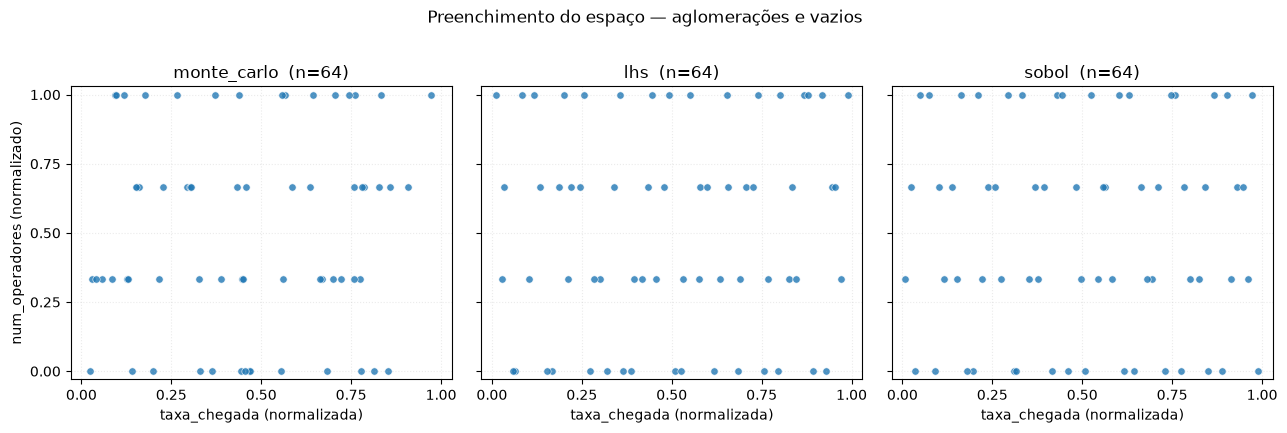

In [6]:
import matplotlib.pyplot as plt

fig, eixos = plt.subplots(1, 3, figsize=(13, 4.2), sharex=True, sharey=True)
for eixo, (nome, d) in zip(eixos, designs.items()):
    U = para_cubo_unitario(d, specs_num)
    eixo.scatter(U[:, 0], U[:, 1], s=28, alpha=0.8, edgecolor="white", linewidth=0.5)
    eixo.set_title(f"{nome}  (n={N})")
    eixo.set_xlabel("taxa_chegada (normalizada)")
    eixo.set_xlim(-0.03, 1.03); eixo.set_ylim(-0.03, 1.03)
    eixo.set_xticks(np.linspace(0, 1, 5)); eixo.set_yticks(np.linspace(0, 1, 5))
    eixo.grid(alpha=0.25, linestyle=":")
eixos[0].set_ylabel("num_operadores (normalizado)")
fig.suptitle("Preenchimento do espaço — aglomerações e vazios", y=1.02)
plt.tight_layout(); plt.show()

O eixo vertical é um fator **inteiro** de 4 níveis, então os pontos se alinham em quatro
faixas nos três métodos — comportamento correto, não artefato. A diferença entre os
métodos aparece no eixo horizontal (contínuo) e na forma como os pontos se distribuem
dentro de cada faixa.

---
## 3. Plano do estudo e replicações

Seguindo a metodologia, o **LHS é o método principal**. Daqui em diante o plano usa o
espaço completo (com o fator categórico).

Cada ponto é executado mais de uma vez porque o simulador é estocástico. A expansão
produz uma linha por execução, com semente derivada de forma determinística do ponto e
do índice da replicação.

In [7]:
from sed_meta.doe.replication import (
    ReplicationPolicy, build_execution_plan,
    aggregate_replications, compute_noise_ceiling,
)

N_PONTOS, N_REP = 40, 5

design = generate_design(specs, n_points=N_PONTOS, seed=SEED, method="lhs")
plano = build_execution_plan(design, ReplicationPolicy(n_replications=N_REP, seed_base=0))

print(f"{N_PONTOS} pontos x {N_REP} replicações = {len(plano)} execuções")
print(f"sementes únicas: {plano['seed'].nunique()}")
plano.head(12)

40 pontos x 5 replicações = 200 execuções
sementes únicas: 200


,point_id,replication_id,seed,taxa_chegada,num_operadores,regra_despacho,turno_extra
0,0,0,0,8.122185,1,SPT,0
1,0,1,1,8.122185,1,SPT,0
2,0,2,2,8.122185,1,SPT,0
3,0,3,3,8.122185,1,SPT,0
4,0,4,4,8.122185,1,SPT,0
5,1,0,5,16.469037,3,FIFO,0
6,1,1,6,16.469037,3,FIFO,0
7,1,2,7,16.469037,3,FIFO,0
8,1,3,8,16.469037,3,FIFO,0
9,1,4,9,16.469037,3,FIFO,0


As cinco primeiras linhas repetem os parâmetros do ponto 0 e variam só a semente — é
exatamente isso que caracteriza a replicação. Os `dtypes` sobrevivem à expansão:

In [8]:
pd.DataFrame({"dtype": plano.dtypes.astype(str)})

,dtype
point_id,int64
replication_id,int64
seed,int64
taxa_chegada,float64
num_operadores,int64
regra_despacho,category
turno_extra,int64


---
## 4. O resultado do DoE

O plano completo e sua descrição estatística.

In [9]:
design.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
taxa_chegada,40.0,NaN,NaN,NaN,12.487003,4.375126,5.290234,8.791379,12.492108,16.236843,19.730463
num_operadores,40.0,NaN,NaN,NaN,2.5,1.132277,1.0,1.75,2.5,3.25,4.0
regra_despacho,40,3,SPT,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
turno_extra,40.0,NaN,NaN,NaN,0.5,0.50637,0.0,0.0,0.5,1.0,1.0


In [10]:
design

,taxa_chegada,num_operadores,regra_despacho,turno_extra
0,8.122185,1,SPT,0
1,16.469037,3,FIFO,0
2,13.310477,3,EDD,0
3,6.366449,3,EDD,0
4,7.159283,1,EDD,1
5,6.707969,3,SPT,1
6,10.875651,4,FIFO,0
7,12.749118,3,SPT,1
8,14.135680,1,EDD,1
9,15.042032,2,SPT,1


---
## 5. Fingindo que a simulação rodou

Substitui-se aqui a campanha no ProModel por uma resposta sintética. Usa-se uma forma
funcional de fila — tempo de atravessamento crescendo de modo não linear com a utilização
e explodindo perto da saturação — com ruído **multiplicativo lognormal**, que reproduz
duas características reais do SED estocástico:

- assimetria à direita (motiva a transformação logarítmica do alvo na etapa 7);
- **heterocedasticidade** — a dispersão entre replicações cresce com a utilização, e é
  isso que dá sentido ao peso amostral calculado na etapa 6.

Na campanha real, esta célula é substituída pelo preenchimento da planilha pelo ProModel;
o restante do notebook não muda.

In [11]:
rng = np.random.default_rng(SEED)

capacidade = plano["num_operadores"].to_numpy(float) * (
    1.0 + 0.25 * plano["turno_extra"].to_numpy(float)
)
# a regra de despacho desloca levemente a capacidade efetiva
efeito_regra = plano["regra_despacho"].map({"FIFO": 1.00, "SPT": 1.12, "EDD": 1.05})
utilizacao = np.clip(
    plano["taxa_chegada"].to_numpy(float)
    / (capacidade * efeito_regra.to_numpy(float) * 7.0),
    0.05, 0.97,
)

resultados = plano.copy()
resultados["lead_time"] = (
    4.0 * utilizacao / (1.0 - utilizacao) * rng.lognormal(0.0, 0.18, len(plano))
)
resultados["throughput"] = 60.0 * utilizacao * capacidade + rng.normal(0.0, 2.0, len(plano))

KPIS = ["lead_time", "throughput"]
resultados[["point_id", "replication_id", "taxa_chegada", "num_operadores",
            "regra_despacho", "lead_time", "throughput"]].head(10)

,point_id,replication_id,taxa_chegada,num_operadores,regra_despacho,lead_time,throughput
0,0,0,8.122185,1,SPT,136.625298,58.875149
1,0,1,8.122185,1,SPT,107.253577,61.014964
2,0,2,8.122185,1,SPT,148.038780,58.381170
3,0,3,8.122185,1,SPT,153.192408,59.487878
4,0,4,8.122185,1,SPT,91.031602,54.099656
5,1,0,16.469037,3,FIFO,11.501179,141.065735
6,1,1,16.469037,3,FIFO,14.877547,139.476712
7,1,2,16.469037,3,FIFO,13.734600,138.725546
8,1,3,16.469037,3,FIFO,14.495201,139.406867
9,1,4,16.469037,3,FIFO,12.469603,140.494925


A heterocedasticidade da resposta sintética, que é o ponto da simulação:

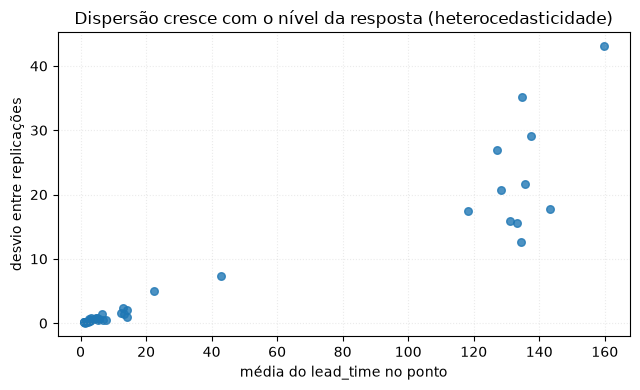

In [12]:
por_ponto = resultados.groupby("point_id")["lead_time"].agg(["mean", "std"])
fig, eixo = plt.subplots(figsize=(6.5, 4))
eixo.scatter(por_ponto["mean"], por_ponto["std"], s=30, alpha=0.8)
eixo.set_xlabel("média do lead_time no ponto")
eixo.set_ylabel("desvio entre replicações")
eixo.set_title("Dispersão cresce com o nível da resposta (heterocedasticidade)")
eixo.grid(alpha=0.25, linestyle=":")
plt.tight_layout(); plt.show()

---
## 6. Duas granularidades, e qual delas treina o metamodelo

Neste ponto há uma decisão que muda o que o metamodelo aprende.

**(A) Por replicação** — as 200 linhas que acabamos de produzir. Cada ponto do DoE aparece
$K$ vezes, com **os mesmos parâmetros de entrada e $K$ resultados diferentes**, porque o
simulador é estocástico.

**(B) Por ponto** — consolidando as $K$ réplicas em uma linha, com a média e estatísticas
de dispersão.

**O treino usa (A).** As $K$ réplicas são a evidência empírica de que aquela combinação de
parâmetros não produz *um* valor, e sim uma distribuição. Entregá-las ao metamodelo é o
que o força a generalizar a tendência em vez de decorar observações: com $K$ alvos
conflitantes sobre o mesmo $X$, não existe função que passe por todos, e o ajuste é
empurrado para a resposta média **por construção** — sem que nenhuma regularização precise
ser imposta de fora. É também a granularidade que preserva a estrutura de replicação de
que métodos com modelagem explícita de ruído dependem.

**(B) continua necessário**, mas para outra coisa: é dele que sai o teto de ruído.

In [13]:
from sed_meta.doe.replication import aggregate_replications, compute_noise_ceiling

param_cols = [s.name for s in specs]
dataset_agregado = aggregate_replications(resultados, param_cols=param_cols, kpi_cols=KPIS)

print(f"(A) por replicação : {len(resultados)} linhas "
      f"({resultados['point_id'].nunique()} pontos x {N_REP} réplicas)  <- treino")
print(f"(B) por ponto      : {len(dataset_agregado)} linhas                        <- teto de ruído")

(A) por replicação : 200 linhas (40 pontos x 5 réplicas)  <- treino
(B) por ponto      : 40 linhas                        <- teto de ruído


As cinco réplicas do ponto 0: **entrada idêntica, saída diferente**. É essa a informação
que a agregação descartaria.

In [14]:
resultados[resultados["point_id"] == 0][
    ["point_id", "replication_id", "seed", "taxa_chegada", "num_operadores",
     "regra_despacho", "lead_time"]
]

,point_id,replication_id,seed,taxa_chegada,num_operadores,regra_despacho,lead_time
0,0,0,0,8.122185,1,SPT,136.625298
1,0,1,1,8.122185,1,SPT,107.253577
2,0,2,2,8.122185,1,SPT,148.038780
3,0,3,3,8.122185,1,SPT,153.192408
4,0,4,4,8.122185,1,SPT,91.031602


### 6.1 Teto de ruído

Decompõe a variância total em variação **entre pontos** (sinal, que um metamodelo pode
aprender) e **entre réplicas do mesmo ponto** (ruído do simulador, que ninguém pode
prever). A razão é o limite superior do $R^2$ legítimo.

Ele precisa ser calculado **na mesma escala em que o modelo treina** — aqui, a do
logaritmo, já que o alvo usa `log_standard`. Comparar um $R^2$ obtido em escala log contra
um teto calculado na escala bruta seria comparar coisas diferentes.

In [15]:
teto_bruto = compute_noise_ceiling(resultados, KPIS)

em_log = resultados.copy()
em_log["lead_time"] = np.log1p(em_log["lead_time"])
teto_log = compute_noise_ceiling(em_log, ["lead_time"])

print(f"lead_time  — teto na escala bruta : {teto_bruto['lead_time']:.4f}")
print(f"lead_time  — teto na escala log   : {teto_log['lead_time']:.4f}  <- a referência")
print(f"throughput — teto na escala bruta : {teto_bruto['throughput']:.4f}")

lead_time  — teto na escala bruta : 0.9503
lead_time  — teto na escala log   : 0.9924  <- a referência
throughput — teto na escala bruta : 0.9961


A consolidação por ponto também produz o peso amostral ($1/\text{variância}$), útil apenas
no caminho (B). No caminho (A) cada linha é uma observação de peso um — a informação sobre
o ruído está nas próprias réplicas, não em um peso.

In [16]:
dataset_agregado[["point_id", "lead_time_mean", "lead_time_std",
                  "lead_time_n", "lead_time_sem"]].head(6)

,point_id,lead_time_mean,lead_time_std,lead_time_n,lead_time_sem
0,0,127.228333,26.947658,5,12.051359
1,1,13.415626,1.411073,5,0.631051
2,2,6.879777,0.499249,5,0.223271
3,3,1.600722,0.227899,5,0.101920
4,4,14.109290,2.011977,5,0.899784
5,5,1.245078,0.076911,5,0.034396


---
## 7. Pré-processamento

A ordem é deliberada e importa: **partição primeiro, ajuste depois**.

- **Entradas (X):** codificadas a partir dos limites *declarados* no `ParameterSpec` —
  não dos observados. Ajustar em qualquer subconjunto das linhas dá o mesmo resultado.
- **Alvo (y):** a transformação é aprendida, e **só** da partição de treino.

### O split tem de ser agrupado por ponto

Com dados por replicação, uma partição comum seria um erro grave: as $K$ réplicas de um
ponto têm **exatamente** os mesmos valores de entrada, então algumas cairiam no treino e
outras no teste — e o modelo seria avaliado prevendo uma linha de $X$ que já viu. Isso não
é generalização, é consulta.

`split()` detecta que há `point_id` repetido e agrupa sozinho. A detecção é automática
justamente porque o erro seria silencioso.

In [17]:
from sed_meta.preprocessing import PreprocessingPipeline, TargetTransformSpec

alvos = [
    TargetTransformSpec("lead_time",  method="log_standard"),
    TargetTransformSpec("throughput", method="standard"),
]

pipe = PreprocessingPipeline(specs, alvos)

train_df, test_df = pipe.split(resultados, test_size=0.25, seed=SEED)   # 1º: particionar
pipe.fit(train_df)                                                      # 2º: ajustar só no treino

X_train = pipe.transform_X(train_df)
X_test  = pipe.transform_X(test_df)
y_train = pipe.transform_y(train_df, "lead_time")
y_test  = pipe.transform_y(test_df,  "lead_time")

print(f"treino : {len(train_df):3d} linhas / {train_df['point_id'].nunique():2d} pontos")
print(f"teste  : {len(test_df):3d} linhas / {test_df['point_id'].nunique():2d} pontos")
print(f"X      : {X_train.shape} treino, {X_test.shape} teste")
print(f"colunas: {pipe.get_feature_names()}")

treino : 150 linhas / 30 pontos
teste  :  50 linhas / 10 pontos
X      : (150, 6) treino, (50, 6) teste
colunas: ['taxa_chegada', 'num_operadores', 'regra_despacho_FIFO', 'regra_despacho_SPT', 'regra_despacho_EDD', 'turno_extra']


In [18]:
# a propriedade que torna a avaliação válida
vazamento = set(train_df["point_id"]) & set(test_df["point_id"])
print(f"pontos presentes nos DOIS lados: {len(vazamento)}   (tem de ser 0)")

# e as réplicas de cada ponto ficaram inteiras de um lado só
print("réplicas por ponto no treino:", sorted(train_df.groupby('point_id').size().unique()))
print("réplicas por ponto no teste :", sorted(test_df.groupby('point_id').size().unique()))

pontos presentes nos DOIS lados: 0   (tem de ser 0)
réplicas por ponto no treino: [np.int64(5)]
réplicas por ponto no teste : [np.int64(5)]


Quanto custaria não agrupar? Basta medir.

In [19]:
from sklearn.model_selection import train_test_split
from sed_meta.metamodels.tree_family import build_random_forest

def r2(y_true, y_pred):
    return 1 - np.sum((y_true - y_pred) ** 2) / np.sum((y_true - y_true.mean()) ** 2)

solto_tr, solto_te = train_test_split(resultados, test_size=0.25, random_state=SEED)
p_solto = PreprocessingPipeline(specs, alvos).fit(solto_tr)
m_solto = build_random_forest().fit(
    p_solto.transform_X(solto_tr), p_solto.transform_y(solto_tr, "lead_time")
)
r2_solto = r2(p_solto.transform_y(solto_te, "lead_time"),
              m_solto.predict(p_solto.transform_X(solto_te)))

print(f"pontos contaminados no teste: "
      f"{len(set(solto_tr['point_id']) & set(solto_te['point_id']))} "
      f"de {solto_te['point_id'].nunique()}")
print(f"R² com split SOLTO (inflado)  : {r2_solto:.4f}")

pontos contaminados no teste: 31 de 32
R² com split SOLTO (inflado)  : 0.9913


Guarde esse número: ele volta na Seção 8.

As três propriedades que o pré-processamento promete:

In [20]:
# (a) entradas: ajustar em 1 linha == ajustar no treino inteiro
print("determinismo das entradas:",
      np.array_equal(pipe.transform_X(train_df.iloc[[0]]), X_train[[0]]))

# (b) réplicas do mesmo ponto produzem X idêntico
primeiro = train_df["point_id"].iloc[0]
X_rep = pipe.transform_X(train_df[train_df["point_id"] == primeiro])
print(f"as {len(X_rep)} réplicas do ponto {primeiro} dão X idêntico:",
      np.allclose(X_rep, X_rep[0]))

# (c) alvo: estatísticas vêm do TREINO, não do conjunto completo
alvo = pipe.targets_["lead_time"]
print(f"média guardada   : {alvo.mean_:.6f}")
print(f"média do treino  : {np.log1p(train_df['lead_time'].to_numpy(float)).mean():.6f}  <- bate")
print(f"média de tudo    : {np.log1p(resultados['lead_time'].to_numpy(float)).mean():.6f}  <- NÃO bate (correto)")

# (d) a transformação do alvo é reversível
volta = pipe.inverse_transform_y(y_test, "lead_time")
print(f"erro máx. no round-trip: {np.abs(volta - test_df['lead_time'].to_numpy(float)).max():.2e}")

determinismo das entradas: True
as 5 réplicas do ponto 0 dão X idêntico: True
média guardada   : 2.688245
média do treino  : 2.688245  <- bate
média de tudo    : 2.602955  <- NÃO bate (correto)
erro máx. no round-trip: 8.53e-14


---
## 8. Metamodelo — Random Forest

Treina-se sobre as réplicas. Não se passa peso amostral: cada linha é uma observação de
peso um.

Duas referências acompanham o resultado, e nenhuma é dispensável — o preditor da média é
o piso (quem não o supera não aprendeu nada) e o teto de ruído é o máximo atingível.

> O modelo opera no espaço **transformado**. A avaliação formal é atribuição da Fase 4,
> ainda não implementada; aqui as métricas servem para confirmar que o treino funciona.

In [21]:
from sed_meta.metamodels.tree_family import GRID_RANDOM_FOREST
from sed_meta.metamodels.baseline import build_dummy_mean

def rmse(y_true, y_pred):
    return float(np.sqrt(np.mean((y_true - y_pred) ** 2)))

modelo = build_random_forest().fit(X_train, y_train)
piso = build_dummy_mean().fit(X_train, y_train)

resumo = pd.DataFrame([
    {"modelo": "Piso (média)",
     "R² treino": r2(y_train, piso.predict(X_train)),
     "R² teste":  r2(y_test,  piso.predict(X_test)),
     "RMSE teste": rmse(y_test, piso.predict(X_test))},
    {"modelo": "Random Forest",
     "R² treino": r2(y_train, modelo.predict(X_train)),
     "R² teste":  r2(y_test,  modelo.predict(X_test)),
     "RMSE teste": rmse(y_test, modelo.predict(X_test))},
]).set_index("modelo")

print(f"teto de ruído na escala do treino: {teto_log['lead_time']:.4f}")
resumo.round(4)

teto de ruído na escala do treino: 0.9924


,R² treino,R² teste,RMSE teste
modelo,,,
Piso (média),0.000,-0.0620,0.8711
Random Forest,0.991,0.6948,0.4670


Repare no $R^2$ de **treino** do Random Forest: ele fica praticamente colado no teto de
ruído. Não é sobreajuste — é o comportamento previsto pela teoria. As réplicas de um
ponto têm $X$ idêntico, então nenhuma árvore consegue separá-las: a folha devolve a média
delas, e a dispersão interna do ponto permanece como resíduo. O erro de treino fica assim
limitado por baixo pelo próprio ruído do simulador, que é exatamente o que o teto mede.

Essa coincidência é uma verificação cruzada barata: o teto de ruído foi calculado por
decomposição de variância, sem olhar modelo nenhum, e o limite empírico do ajuste caiu no
mesmo lugar.

### 8.1 Por que o split agrupado não era preciosismo

Vale confrontar os dois números:

| | R² teste |
|---|---:|
| Split agrupado (correto) | ver acima |
| Split solto (Seção 7) | ver acima |
| **Teto de ruído** | **ver acima** |

O split solto produz um $R^2$ que chega **praticamente ao teto de ruído** — isto é, o
modelo pareceria explicar quase toda a variância explicável de um sistema de 4 fatores a
partir de 30 pontos. É implausível, e a razão é simples: ele não estava prevendo, estava
recuperando linhas que já tinha visto.

Note que o teto **não flagra formalmente** o caso: o valor inflado fica logo abaixo dele,
não acima. O teto é um auxílio de diagnóstico, não uma garantia — quem impede o erro é o
split agrupado.

In [22]:
pd.DataFrame({
    "R² teste": {
        "split agrupado (correto)": r2(y_test, modelo.predict(X_test)),
        "split solto (contaminado)": r2_solto,
        "teto de ruído": teto_log["lead_time"],
    }
}).round(4)

,R² teste
split agrupado (correto),0.6948
split solto (contaminado),0.9913
teto de ruído,0.9924


### 8.2 Busca de hiperparâmetros

O grid sugerido para esta família **não inclui o número de árvores**: em *bagging* o erro
converge conforme se acrescentam árvores, sem sobreajustar, então buscar nesse eixo gasta
orçamento por uma resposta já conhecida.

A validação cruzada também precisa respeitar os grupos, pelo mesmo motivo da Seção 7 —
daí `GroupKFold` com os `point_id` do treino.

In [23]:
GRID_RANDOM_FOREST

{'max_depth': [None, 4, 8, 16],
 'min_samples_leaf': [1, 2, 3, 5, 10],
 'max_features': [1.0, 0.5, 'sqrt']}

In [24]:
from sklearn.model_selection import GridSearchCV, GroupKFold

busca = GridSearchCV(build_random_forest(), GRID_RANDOM_FOREST,
                     cv=GroupKFold(n_splits=4), scoring="r2", n_jobs=-1)
busca.fit(X_train, y_train, groups=train_df["point_id"])

print("melhores hiperparâmetros:", busca.best_params_)
print(f"R² em validação cruzada (agrupada) : {busca.best_score_:.4f}")
print(f"R² no teste (hold-out)             : {r2(y_test, busca.best_estimator_.predict(X_test)):.4f}")

melhores hiperparâmetros: {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 2}
R² em validação cruzada (agrupada) : 0.7781
R² no teste (hold-out)             : 0.7905


As previsões voltam à escala original — minutos — pela transformação inversa do alvo. É
disso que a Fase 4 precisará para reportar RMSE e MAE em unidades interpretáveis.

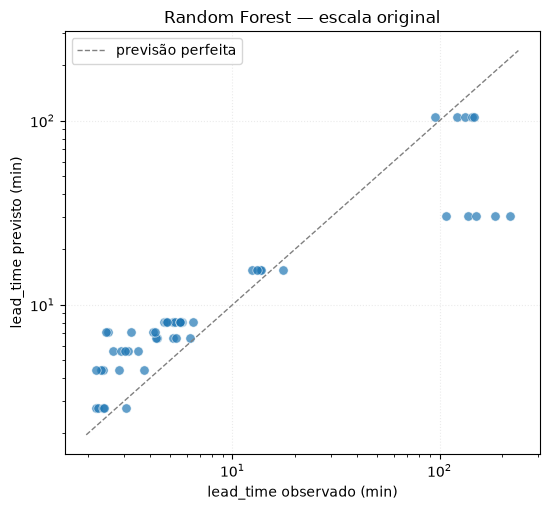

MAE na escala original: 17.43 min


In [25]:
previsto_min = pipe.inverse_transform_y(busca.best_estimator_.predict(X_test), "lead_time")
observado_min = test_df["lead_time"].to_numpy(float)

fig, eixo = plt.subplots(figsize=(5.6, 5.2))
lim = [min(observado_min.min(), previsto_min.min()) * 0.9,
       max(observado_min.max(), previsto_min.max()) * 1.1]
eixo.plot(lim, lim, "--", color="gray", linewidth=1, label="previsão perfeita")
eixo.scatter(observado_min, previsto_min, s=45, alpha=0.7, edgecolor="white", linewidth=0.5)
eixo.set_xscale("log"); eixo.set_yscale("log")
eixo.set_xlabel("lead_time observado (min)")
eixo.set_ylabel("lead_time previsto (min)")
eixo.set_title("Random Forest — escala original")
eixo.legend(); eixo.grid(alpha=0.25, linestyle=":")
plt.tight_layout(); plt.show()

print(f"MAE na escala original: {np.mean(np.abs(previsto_min - observado_min)):.2f} min")

Cada ponto de teste aparece **cinco vezes** no gráfico — uma por réplica — com o mesmo
valor previsto e valores observados diferentes. A dispersão vertical de cada grupo é o
ruído do simulador, que o metamodelo não pode nem deve reproduzir: ele prevê a tendência,
e a dispersão em torno dela é exatamente o que o teto de ruído quantifica.

---
## Resumo

O percurso confirmou que a cadeia implementada faz o que precisa fazer:

| Etapa | Verificado |
|---|---|
| Espaço de parâmetros | Quatro naturezas de fator declaradas fora do código |
| Amostragem | Os três métodos são **distintos**; Monte Carlo funciona como *baseline* |
| Preenchimento do espaço | Sete métricas comparando os três métodos |
| Replicações | Uma linha por execução, sementes determinísticas, `dtypes` preservados |
| Resultado do DoE | `.describe()` e o *DataFrame* completo |
| Simulação (fingida) | KPIs assimétricos e heterocedásticos, como o SED real |
| Granularidade | Treino sobre **réplicas**; agregação usada para o teto de ruído |
| Teto de ruído | Calculado, com o limite do $R^2$ atingível |
| Pré-processamento | Split **agrupado por ponto**, entradas determinísticas, alvo sem vazamento |
| Metamodelo | Random Forest sobre réplicas, `GroupKFold` na busca, volta à escala original |

**Fora deste notebook, por não estarem implementadas:** a avaliação estatística formal
(Fase 4) e a camada de explicabilidade (Fase 5).